# Do KODIAK's tokens encode tissue niches better than DINOv3's? — a matched comparison

Notebook 01 answers this by comparing two *codebooks*: KODIAK's learned prototype layer against a k-means fit on
DINOv3 tokens. Three things make that comparison unable to support the claim:

1. **The codebooks live in different spaces.** KODIAK's prototypes are `(128, projector_dim)` — they index the
   projector output the pretraining loss operates on — while the DINOv3 centroids are `(128, embed_dim)` in token
   space. Their similarity matrices, families and hues are therefore not comparable objects.
2. **One codebook is trained, the other is fitted afterwards.** KODIAK's prototypes are optimized end to end by the
   prototype-CLS loss; DINOv3's are post-hoc k-means. Any difference in code geometry may be an artifact of
   *learned vs clustered*, not of the representation.
3. **Agreement is measured against a clustering, not a reference.** The "reference niches" are themselves k-means on
   expert-cell windows, so ARI/NMI against them measures agreement with one arbitrary partition, with no held-out
   split, no seed repetition, and no baseline that a trivial feature would also pass.

This notebook asks the same question with the asymmetry removed. Everything either encoder receives is identical:
the same regions, the same windows, the same token grid, the same labels, the same probe, the same folds, the same
k-means procedure. Three results, in increasing order of how much they are worth:

* **§2 Probes (the quantitative result).** Predict each token's niche and lineage from its features, with
  leave-one-region-out folds, standardization fitted inside each fold, and a PCA control so a wider encoder cannot
  win on width alone. A **marker baseline** — the mean and s.d. of the input channels in that token — runs in every
  fold: any encoder that does not beat it has added nothing.
* **§3 Codebooks (matched, unsupervised).** The *same* k-means procedure on both encoders' tokens, at several K and
  several seeds, scored against the expert niches. This replaces the trained-vs-fitted comparison.
* **§4 KODIAK's learned prototypes**, reported on their own as a property of the pretraining run — never placed
  beside a k-means codebook as if the two were the same kind of object.

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
import json, os, shutil, tempfile, time
from pathlib import Path
import numpy as np, pandas as pd, torch, yaml
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest
from mxdata.io import Box
from mxdata.data.composite import render_channels
from mxseg.evaluate import split_regions_of
from mxseg.inputs import dataset_norms
from kodiak import Kodiak
from kodiak.components import DinoV3Encoder

# ---- edit here ---------------------------------------------------------------------------------------------------------
RUN_NAME = "kodiak_mxif_vitb"                      # the pretraining run, found under runs_v2/ or runs/; its ARCHITECTURE and
#                                                    its DINOv3 initialization are read from the run, never set here
SLIDE = "SLIDE-0236"                               # the slide analysed: the held-out one, so neither encoder trained on it
GREEN = "PanCK"                                    # marker read into green (pretraining drew it at random per sample)
CKPT = "last.ckpt"                                 # or a fixed one, e.g. "kodiak-epoch=099.ckpt"
PCA_DIM = 64                                       # width-matched probe: both encoders reduced to this many components
SEEDS = (0, 1, 2)                                  # k-means repeats; every reported number is a mean +/- s.d. over these
K_GRID = (4, 16, 128)                              # codebook sizes, identical for both encoders
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
cfg = load_config(REPO / "configs" / "dataset.yaml")

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
NICHE_COLOR = {"Immune-infiltrated": "#C43E4E", "Epithelial core": "#2A78D6",
               "Interface": "#9A86E0", "Stromal / other": "#B9BDC4"}
FEAT_COLOR = {"KODIAK": "#C43E4E", "DINOv3": "#B08A2E", "markers": "#8A9099"}

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def short(key):
    return key.split("_")[-1]

CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def chip(ax, text):
    """A short label inside an image panel — never a sentence."""
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=6.8, fontweight="bold", color="white", va="top", bbox=CHIP)

def scalebar(ax, npx, um=50, color="white"):
    L = um / PX_UM
    x1, y = npx * 0.96, npx * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.0, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx * 0.03, f"{um} µm", color=color, ha="center", va="bottom", fontsize=6.4)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

# ---- the two encoders, built from the run's own architecture -------------------------------------------------------------
torch.set_grad_enabled(False)
torch.set_num_threads(max(2, (os.cpu_count() or 8) // 2))                      # CPU only: the GPU belongs to the training run
RUN = next((p for p in (REPO / "runs_v2" / RUN_NAME, REPO / "runs" / RUN_NAME) if p.is_dir()), None)
if RUN is None:
    raise FileNotFoundError(f"no run {RUN_NAME!r} under runs_v2/ or runs/")
run_cfg = yaml.safe_load((RUN / "resolved_config.yaml").read_text())
M = run_cfg["model"]
ARCH = dict(patch_size=M.get("vit_patch_size", 16), embed_dim=M.get("vit_embed_dim", 384),
            depth=M.get("vit_depth", 12), num_heads=M.get("vit_heads", 6),
            mlp_ratio=M.get("vit_mlp_ratio", 4.0), num_storage_tokens=M.get("num_storage_tokens", 4))
DEC = dict(decoder_embed_dim=M.get("decoder_dim", 192), decoder_depth=M.get("decoder_depth", 4),
           decoder_num_heads=M.get("decoder_heads", 6))
D = ARCH["embed_dim"]
CHANNELS = (run_cfg["data"]["input"]["red"], GREEN, run_cfg["data"]["input"]["blue"])
MARKERS = [m for m in CHANNELS if m]

src_ckpt, tmp_ckpt = RUN / "checkpoints" / CKPT, Path(tempfile.gettempdir()) / "niches_matched.ckpt"
if not src_ckpt.is_file():
    have = sorted(x.name for x in (RUN / "checkpoints").glob("*.ckpt")) if (RUN / "checkpoints").is_dir() else []
    raise FileNotFoundError(f"{src_ckpt.relative_to(REPO)} not found; have: {have}")
for attempt in range(3):                           # last.ckpt is rewritten at every epoch end: copy, retry if caught mid-write
    try:
        shutil.copy2(src_ckpt, tmp_ckpt)
        ck = torch.load(tmp_ckpt, map_location="cpu", weights_only=False)
        break
    except Exception:
        if attempt == 2:
            raise
        time.sleep(5)
EPOCH = int(ck["epoch"])
kodiak = Kodiak(num_prototypes=M.get("num_prototypes", 128), projector_dim=M.get("projector_dim", 256),
                img_size=M.get("image_size", 256), **ARCH, **DEC).eval()
state = {k.split("model.", 1)[1]: v for k, v in ck["state_dict"].items() if k.startswith("model.")}
missing, _ = kodiak.load_state_dict(state, strict=False)
assert not [m for m in missing if "teacher" in m or "prototype" in m], missing

WEIGHTS = REPO / M["pretrained_path"]              # the DINOv3 this run started from: the same architecture by construction
dino = DinoV3Encoder(**ARCH).eval()
dstate = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
dino.load_state_dict(dstate.get("model", dstate), strict=True)

# THE ONE ASYMMETRY THAT REMAINS IS THE WEIGHTS. Both encoders are read through the identical call: the same forward, the
# same tokens, the same grid. Nothing that touches KODIAK's prototype layer appears here -- that belongs to section 4.
ENC = {"KODIAK": lambda xb: kodiak.teacher_encoder.forward_full(xb)[1],
       "DINOv3": lambda xb: dino.forward_full(xb)[1]}

# ---- the exact pretraining input -----------------------------------------------------------------------------------------
paths, mx, _ = ingest(SLIDE, None)
NORMS = dataset_norms(DEFAULT_DATASET, cfg.slides, MARKERS)[SLIDE]
IN_MEAN = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]
IN_STD = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]
G = ARCH["patch_size"]
PX_UM = float(mx.pixel_size_um or 0.325)

def composite(stack):
    return render_channels(stack, MARKERS, NORMS, CHANNELS)

def to_input(rgb):
    return ((rgb - IN_MEAN) / IN_STD).astype(np.float32)

def marker01(stack):
    return np.stack([np.clip((stack[c].astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1)
                     for c, (lo, hi) in enumerate(NORMS[m] for m in MARKERS)])

def encode_windows(x, fn, size=256, stride=128, batch=8):
    """Token grid of a (3, H, W) input from 256^2 windows on a 128-px lattice -- the training resolution -- Hann-blended
    where windows overlap. Identical for both encoders, so no difference here can come from how they were read."""
    H, W = x.shape[1:]
    ys = sorted({*range(0, H - size + 1, stride), H - size})
    xs = sorted({*range(0, W - size + 1, stride), W - size})
    wins = [(y, xx) for y in ys for xx in xs]
    g = size // G
    hann = np.hanning(g + 2)[1:-1]
    wgt = (np.outer(hann, hann) + 1e-3)[..., None].astype(np.float32)
    acc, cnt = None, np.zeros((H // G, W // G, 1), np.float32)
    for i in range(0, len(wins), batch):
        chunk = wins[i:i + batch]
        o = fn(torch.from_numpy(np.stack([x[:, y:y + size, xx:xx + size] for y, xx in chunk]))).numpy()
        if acc is None:
            acc = np.zeros((H // G, W // G, o.shape[-1]), np.float32)
        for j, (y, xx) in enumerate(chunk):
            ty, tx = y // G, xx // G
            acc[ty:ty + g, tx:tx + g] += o[j].reshape(g, g, -1) * wgt
            cnt[ty:ty + g, tx:tx + g] += wgt
    return acc / cnt

print(f"KODIAK: {src_ckpt.relative_to(REPO)} @ epoch {EPOCH} (step {ck['global_step']}) | DINOv3: {WEIGHTS.name} | "
      f"ViT {D}d x {ARCH['depth']} x {ARCH['num_heads']}h, patch {G} | slide {SLIDE}, input {MARKERS}")

KODIAK: runs/kodiak_mxif_vitb/checkpoints/last.ckpt @ epoch 65 (step 41448) | DINOv3: dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth | ViT 768d x 12 x 12h, patch 16 | slide SLIDE-0236, input ['LAP2', 'PanCK', 'DAPI']


## 1. One token table: both encoders, the same tokens, the same labels

Every region of the held-out split goes through both encoders by the identical path above. Expert cells are placed on
the token grid, and a token inherits the majority niche and lineage of the cells inside it. Tokens with no expert cell
carry no label and are used only where that is stated. The niche reference is the paper's fixed pipeline (10-cell
Schürch windows, k-means over lineage composition), computed **once** and shared by both encoders — it is a property of
the annotation, not of either model.

In [2]:
from sklearn.cluster import MiniBatchKMeans

by_split = {s: split_regions_of(DEFAULT_DATASET, s, cfg.slides).get(SLIDE, []) for s in ("test", "val", "train")}
SPLIT = next((s for s in ("test", "val", "train") if by_split[s]), None)
if SPLIT is None:
    raise ValueError(f"no labeled regions for {SLIDE}")
ids = sorted(by_split[SPLIT])
print(f"{SLIDE}: {len(ids)} {SPLIT} regions {ids}" + ("  (SEEN IN PRETRAINING -- read section 2 accordingly)" if SPLIT == "train" else ""))
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}

# ---- expert cells: the stored table if it covers these regions, else computed the same way and cached per slide ----------
CLASSES = ["Epithelial", "Immune", "Other"]
W_CN, NCN = 10, 4

def load_expert_cells(keys):
    need = set(keys)
    for f in (ANALYSIS / "cells_expert.csv", ANALYSIS / f"cells_expert_{SLIDE}.csv"):
        if f.is_file():
            e = pd.read_csv(f)
            if need <= set(e.region.unique()):
                return e[e.region.isin(need)].reset_index(drop=True)
    from mxdata import apply_qc_policy
    from mxdata.data import LiveSource
    from mxdata.pipeline.stats import NormStats
    from mxseg.analysis import assign_phenotypes, cell_marker_table, gate_phenotypes, load_panel, phenotype_gates
    PANEL = ["PanCK", "CD45", "CD3", "CD4", "CD8", "FOXP3", "uPAR"]
    live = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
    frames = []
    for key in live.keys:
        rs = live.load(key)
        labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
        gt = labels.copy()
        for g in np.unique(gt[ignore]):
            if g:
                gt[gt == g] = 0
        box = regions[int(key.split("_R")[-1])].box
        t = cell_marker_table(gt, mx.read_region(box, markers=PANEL, level=0).astype(np.float32), PANEL)
        t["region"] = key
        frames.append(t)
    e = pd.concat(frames, ignore_index=True)
    panel_ = load_panel(REPO / "configs" / "panel.yaml")                          # the panel's gates (calibrated on the tags, notebook 09)
    st_ = NormStats.load(DEFAULT_DATASET / SLIDE / "stats.json")
    thr_ = phenotype_gates(e, panel_, norms={mk: (float(st_.lo[mk]), float(st_.hi[mk])) for mk in panel_.gate_markers})
    e["pheno"] = gate_phenotypes(e, {mk: thr_[mk] for mk in ("PanCK", "CD45")})
    e["cell_type"], e["lineage"] = assign_phenotypes(e, panel_, thr_)
    ANALYSIS.mkdir(parents=True, exist_ok=True)
    f = ANALYSIS / f"cells_expert_{SLIDE}.csv"
    e.to_csv(f, index=False)
    print(f"expert cells computed and cached -> {f.relative_to(REPO)} ({len(e)} cells)")
    return e

KEYS = [f"{SLIDE}_R{rid:02d}" for rid in regions]
expert = load_expert_cells(KEYS)
missing_ann = [k for k in KEYS if not (expert.region == k).any()]
if missing_ann:
    raise ValueError(f"no expert cells for {missing_ann}")

def windows(cy, cx, pheno):
    """Schuerch windows: lineage frequencies among the W_CN nearest cells, the centre included."""
    idx = {c: i for i, c in enumerate(CLASSES)}
    pts = np.column_stack([cy, cx])
    _, nn = cKDTree(pts).query(pts, k=min(W_CN, len(pts)))
    ph = np.array([idx[p] for p in pheno])
    comp = np.zeros((len(pts), len(CLASSES)))
    for i, row in enumerate(nn):
        for j in np.atleast_1d(row):
            comp[i, ph[j]] += 1
    return comp / np.maximum(comp.sum(1, keepdims=True), 1)

ecomp, frames = [], []
for key in KEYS:
    e = expert[expert.region == key].reset_index(drop=True)
    ecomp.append(windows(e.cy.values, e.cx.values, list(e.pheno)))
    frames.append(e)
km = MiniBatchKMeans(NCN, n_init=10, random_state=0).fit(np.vstack(ecomp))
cc_ = km.cluster_centers_; NAME = {}; left_ = list(range(NCN))                    # every name used once, by rank (as notebook 05)
imm = max(left_, key=lambda c: cc_[c, CLASSES.index("Immune")]); NAME[imm] = "Immune-infiltrated"; left_.remove(imm)
core = max(left_, key=lambda c: cc_[c, CLASSES.index("Epithelial")]); NAME[core] = "Epithelial core"; left_.remove(core)
inter = max(left_, key=lambda c: cc_[c, CLASSES.index("Epithelial")]); NAME[inter] = "Interface"; left_.remove(inter)
NAME[left_[0]] = "Stromal / other"
expert = pd.concat(frames, ignore_index=True)
expert["niche"] = [NAME[c] for c in km.labels_]

# ---- both encoders over every region, then one long table ----------------------------------------------------------------
t0 = time.perf_counter()
FEAT, MAPS, rows = {tag: [] for tag in ENC}, {}, []
for rid, r in regions.items():
    key = f"{SLIDE}_R{rid:02d}"
    stack = mx.read_region(r.box, markers=MARKERS, level=0)
    H, W = (stack.shape[1] // G) * G, (stack.shape[2] // G) * G
    stack = stack[:, :H, :W]
    rgb = composite(stack)
    m01 = marker01(stack)
    h, w = H // G, W // G
    toks = {tag: encode_windows(to_input(rgb), fn) for tag, fn in ENC.items()}      # identical call for both
    MAPS[key] = dict(rgb=rgb.transpose(1, 2, 0), shape=(h, w))
    e = expert[expert.region == key]
    ty, tx = (e.cy // G).astype(int).values, (e.cx // G).astype(int).values
    ok = (ty < h) & (tx < w)
    e = e[ok].assign(t=ty[ok] * w + tx[ok])
    maj = lambda col: e.groupby("t")[col].agg(lambda s: s.value_counts().index[0])
    niche, lineage = np.full(h * w, "none", object), np.full(h * w, "none", object)
    niche[maj("niche").index] = maj("niche").values
    lineage[maj("pheno").index] = maj("pheno").values
    mean, sd = m01.reshape(3, h, G, w, G).mean((2, 4)), m01.reshape(3, h, G, w, G).std((2, 4))
    df = pd.DataFrame({"region": key, "ty": np.repeat(np.arange(h), w), "tx": np.tile(np.arange(w), h),
                       "n_cells": np.bincount(e.t, minlength=h * w), "niche": niche, "lineage": lineage})
    for c, m in enumerate(MARKERS):                                                 # the marker baseline's features
        df[f"{m}_mean"], df[f"{m}_sd"] = mean[c].ravel(), sd[c].ravel()
    rows.append(df)
    for tag in ENC:
        FEAT[tag].append(toks[tag].reshape(h * w, -1))
TOK = pd.concat(rows, ignore_index=True)
X = {tag: np.concatenate(v).astype(np.float32) for tag, v in FEAT.items()}
X["markers"] = TOK[[c for c in TOK.columns if c.endswith(("_mean", "_sd"))]].values.astype(np.float32)
LAB = TOK.n_cells.values > 0
print(f"{len(regions)} regions x {len(ENC)} encoders in {time.perf_counter() - t0:.0f} s | "
      f"{len(TOK)} tokens, {LAB.sum()} labelled ({LAB.mean():.0%}) | features " +
      ", ".join(f"{k} {v.shape[1]}d" for k, v in X.items()))
print("niches:", ", ".join(f"{k} {v}" for k, v in TOK[LAB].niche.value_counts().items()))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})
/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


SLIDE-0236: 6 test regions [1, 2, 3, 4, 5, 6]


expert cells computed and cached -> outputs/analysis/cells_expert_SLIDE-0236.csv (6152 cells)


6 regions x 2 encoders in 379 s | 35511 tokens, 6052 labelled (17%) | features KODIAK 768d, DINOv3 768d, markers 6d
niches: Stromal / other 1996, Immune-infiltrated 1816, Epithelial core 1259, Interface 981


## 2. Probes: can a token's features predict its niche, held out by region?

The question notebook 01 was reaching for, asked so that an answer means something. For each feature set — KODIAK
tokens, DINOv3 tokens, and the **marker baseline** (mean and s.d. of the three input channels in that token) — a
multinomial logistic regression predicts the token's niche, then its lineage, under **leave-one-region-out** folds.
Standardization and PCA are fitted **inside the training fold only**. Two probe widths are reported: the encoder's
full token width, and `PCA_DIM` components, so no encoder can win on width
alone (both are ViT-B here, 768-d tokens; the control is kept so the comparison stays valid for any pair). Scores are balanced accuracy and macro F1 — the niches are heavily imbalanced, so plain accuracy would be
won by predicting *Epithelial core* everywhere.

In [3]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TARGETS = ("niche", "lineage")
REGIONS = sorted(TOK.region.unique())

def probe(Xf, y, groups, dim=None, seed=0):
    """Leave-one-region-out multinomial logistic regression. Everything fitted -- scaler, PCA, model -- sees the training
    fold only. Returns one (balanced accuracy, macro F1) per held-out region."""
    out = []
    for held in REGIONS:
        tr, te = groups != held, groups == held
        if len(np.unique(y[tr])) < 2 or te.sum() == 0:
            continue
        steps = [StandardScaler()]
        if dim is not None and dim < Xf.shape[1]:
            steps.append(PCA(dim, random_state=seed))
        steps.append(LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0, random_state=seed))
        pipe = make_pipeline(*steps).fit(Xf[tr], y[tr])
        p = pipe.predict(Xf[te])
        out.append((balanced_accuracy_score(y[te], p), f1_score(y[te], p, average="macro")))
    return np.array(out)

t0 = time.perf_counter()
res = []
for target in TARGETS:
    y = TOK[target].values[LAB]
    groups = TOK.region.values[LAB]
    for tag, Xf in X.items():
        for dim, width in ((None, "full"), (PCA_DIM, f"PCA {PCA_DIM}")):
            if width.startswith("PCA") and Xf.shape[1] <= PCA_DIM:
                continue                                                   # the marker baseline is already narrower
            s = probe(Xf[LAB], y, groups, dim=dim)
            res.append(dict(target=target, features=tag, width=width, n_folds=len(s),
                            bacc=s[:, 0].mean(), bacc_sd=s[:, 0].std(), f1=s[:, 1].mean(), f1_sd=s[:, 1].std()))
PROBE = pd.DataFrame(res)
print(f"{len(PROBE)} probes x {len(REGIONS)} folds in {time.perf_counter() - t0:.0f} s\n")
print(PROBE.pivot_table(index=["target", "features"], columns="width", values="bacc")
      .round(3).to_string())

/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


10 probes x 6 folds in 50 s

width             PCA 64   full
target  features               
lineage DINOv3     0.629  0.559
        KODIAK     0.686  0.656
        markers      NaN  0.686
niche   DINOv3     0.518  0.436
        KODIAK     0.505  0.502
        markers      NaN  0.496


**Figure 1 — Held-out niche and lineage prediction from token features.** Bars are the mean balanced accuracy over
leave-one-region-out folds, whiskers the s.d. across folds. The dashed line is chance (1/number of classes). The grey
bar is the marker baseline: features that any thresholding pipeline already has. An encoder earns its place only by
clearing it, and the two encoders are separated only where their error bars do not overlap. The right-hand panels
repeat the comparison at a common width, so no result can be attributed to one encoder having wider tokens.

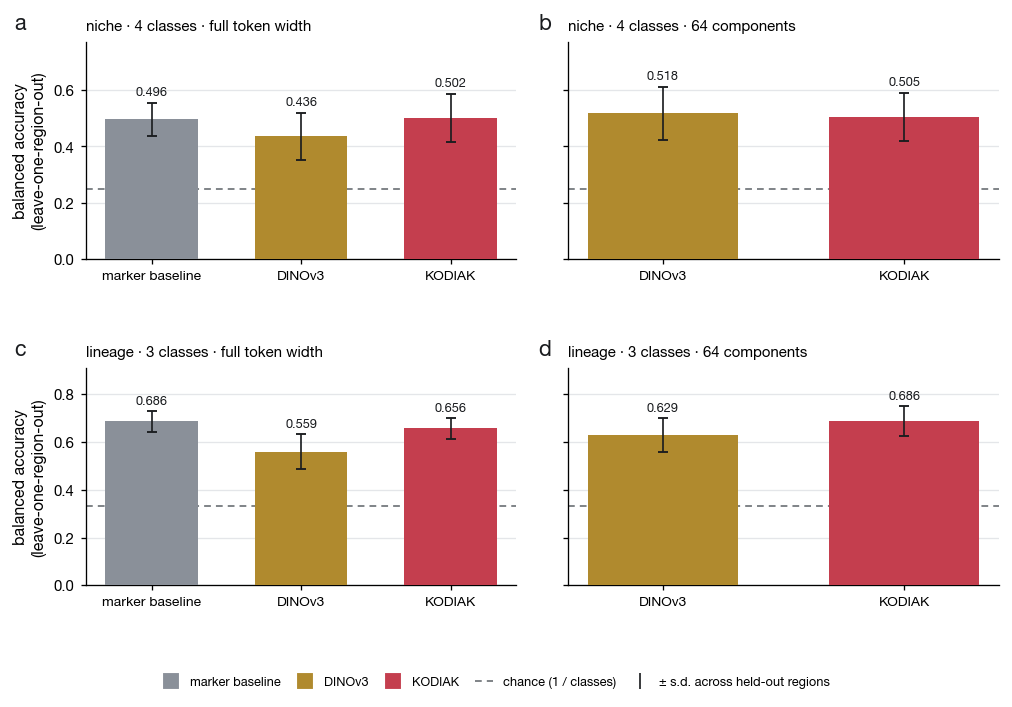

In [4]:
LABEL_F = {"markers": "marker baseline", "DINOv3": "DINOv3", "KODIAK": "KODIAK"}
fig, axes = plt.subplots(len(TARGETS), 2, figsize=(7.6, 2.4 * len(TARGETS) + 0.5), sharey="row")
fig.subplots_adjust(left=0.1, right=0.99, top=0.92, bottom=0.16, wspace=0.12, hspace=0.5)
for r, target in enumerate(TARGETS):
    n_cls = TOK[LAB][target].nunique()
    for c, width in enumerate(["full", f"PCA {PCA_DIM}"]):
        ax = axes[r, c]
        d = PROBE[(PROBE.target == target) & (PROBE.width == width)]
        if d.empty:
            ax.set_axis_off(); continue
        d = d.set_index("features").reindex([f for f in ("markers", "DINOv3", "KODIAK") if f in set(d.features)])
        xs = np.arange(len(d))
        ax.bar(xs, d.bacc, yerr=d.bacc_sd, width=0.62, color=[FEAT_COLOR[f] for f in d.index],
               error_kw=dict(lw=0.9, capsize=2.5, ecolor=INK), zorder=3)
        ax.axhline(1 / n_cls, ls=(0, (4, 3)), lw=0.9, color=MUTED, zorder=2)
        for x, (v, s) in enumerate(zip(d.bacc, d.bacc_sd)):
            ax.text(x, v + s + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=6.8, color=INK)
        ax.set_xticks(xs, [LABEL_F[f] for f in d.index], fontsize=7.4)
        top = float(max(d.bacc + d.bacc_sd))
        ax.set_ylim(0, min(1.0, top + 0.16))
        ax.set_title(f"{target} · {n_cls} classes · {'full token width' if width == 'full' else f'{PCA_DIM} components'}", fontsize=8)
        if c == 0:
            ax.set_ylabel("balanced accuracy\n(leave-one-region-out)")
        ygrid(ax); panel(ax, "abcd"[r * 2 + c], dx=-0.14 if c == 0 else -0.04)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=FEAT_COLOR[f], label=LABEL_F[f]) for f in ("markers", "DINOv3", "KODIAK")] + \
          [plt.Line2D([], [], ls=(0, (4, 3)), lw=0.9, color=MUTED, label="chance (1 / classes)"),
           plt.Line2D([], [], marker="|", ls="", ms=9, mew=0.9, color=INK, label="± s.d. across held-out regions")]
fig.legend(handles=handles, ncol=5, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=6.8, handlelength=1.4, columnspacing=1.2)
plt.show()

## 3. Codebooks, matched: the same k-means on both encoders

Section 2 asks what the features *contain*. This asks whether that content is organized into discoverable clusters —
the question notebook 01 asked with a trained codebook on one side and k-means on the other. Here the procedure is
identical for both encoders: L2-normalize the tokens, fit MiniBatch k-means at each K, score the partition against the
expert niches with NMI and ARI, and repeat over `SEEDS`. NMI grows with K, so only the same-K columns may be compared
across encoders — never across K.

In [5]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def unit(a):
    return a / np.maximum(np.linalg.norm(a, axis=1, keepdims=True), 1e-9)

t0 = time.perf_counter()
y_niche = TOK.niche.values[LAB]
rows = []
for tag in ("KODIAK", "DINOv3"):
    Z = unit(X[tag])
    for K in K_GRID:
        for seed in SEEDS:
            lab = MiniBatchKMeans(K, n_init=3, random_state=seed, batch_size=4096).fit_predict(Z)[LAB]
            rows.append(dict(features=tag, K=K, seed=seed,
                             nmi=normalized_mutual_info_score(y_niche, lab),
                             ari=adjusted_rand_score(y_niche, lab)))
CODE = pd.DataFrame(rows)
print(f"{len(CODE)} k-means fits in {time.perf_counter() - t0:.0f} s\n")
print(CODE.groupby(["features", "K"])[["nmi", "ari"]].agg(["mean", "std"]).round(3).to_string())

18 k-means fits in 79 s

                nmi           ari       
               mean    std   mean    std
features K                              
DINOv3   4    0.258  0.028  0.227  0.030
         16   0.229  0.010  0.147  0.023
         128  0.227  0.002  0.041  0.004
KODIAK   4    0.186  0.031  0.163  0.055
         16   0.187  0.003  0.126  0.005
         128  0.174  0.001  0.025  0.002


**Figure 2 — Matched codebooks against the expert niches.** Same tokens, same k-means, same K, three seeds; points
are seeds, bars the mean. Compare only within a K.

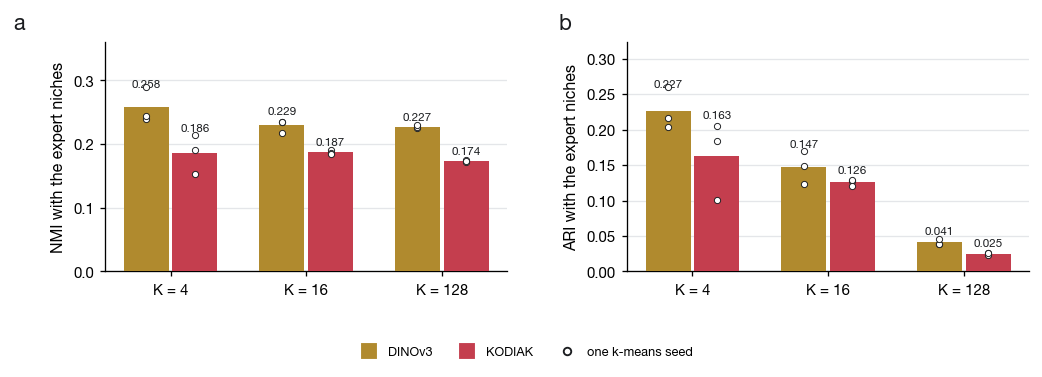

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.7))
fig.subplots_adjust(left=0.09, right=0.99, top=0.9, bottom=0.27, wspace=0.3)
w, xs = 0.36, np.arange(len(K_GRID))
for ax, metric, name in zip(axes, ("nmi", "ari"), ("NMI", "ARI")):
    top = 0
    for i, tag in enumerate(("DINOv3", "KODIAK")):
        g = CODE[CODE.features == tag].groupby("K")[metric]
        mu, sd = g.mean().reindex(K_GRID), g.std(ddof=0).reindex(K_GRID)
        ax.bar(xs + (i - 0.5) * w, mu, w * 0.92, color=FEAT_COLOR[tag], zorder=3)
        for j, K in enumerate(K_GRID):
            pts = CODE[(CODE.features == tag) & (CODE.K == K)][metric]
            ax.scatter(np.full(len(pts), xs[j] + (i - 0.5) * w), pts, s=11, color="white", edgecolor=INK, lw=0.5, zorder=4)
            ax.text(xs[j] + (i - 0.5) * w, float(mu[K]) + float(sd[K]) + 0.006, f"{mu[K]:.3f}", ha="center", va="bottom", fontsize=6.2, color=INK)
            top = max(top, float(mu[K]) + float(sd[K]))
    ax.set_xticks(xs, [f"K = {K}" for K in K_GRID]); ax.set_ylabel(f"{name} with the expert niches"); ax.set_ylim(0, top * 1.25 + 0.01)
    ygrid(ax); panel(ax, "ab"[list(axes).index(ax)], dx=-0.2 if ax is axes[0] else -0.14)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=FEAT_COLOR[t], label=t) for t in ("DINOv3", "KODIAK")] + \
          [plt.Line2D([], [], marker="o", ls="", ms=4, mfc="white", mec=INK, label="one k-means seed")]
fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=6.8, handlelength=1.4)
plt.show()

## 4. KODIAK's learned prototypes — reported, not compared

The prototype layer is `(num_prototypes, projector_dim)`: it indexes the **projector** output the pretraining loss
operates on, not the token space section 3 clusters. There is no DINOv3 counterpart, so nothing here is a comparison.
What it does report is whether pretraining is using its codebook at all — a collapsed codebook (a few prototypes
holding all the mass) is a property of the run worth knowing while it trains.

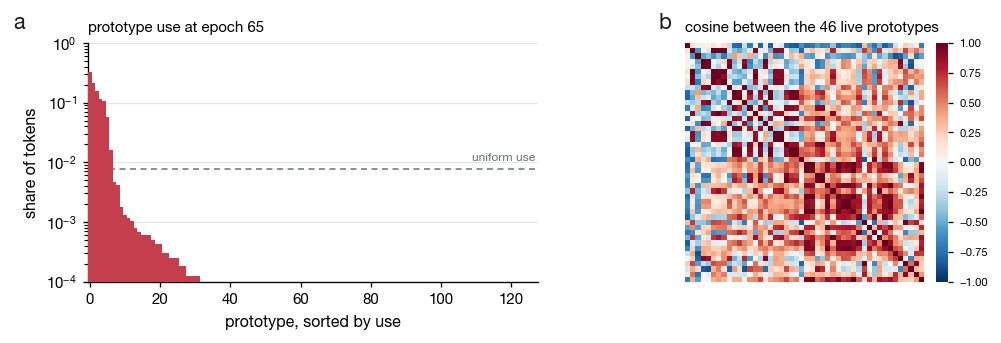

epoch 65: 46 of 128 prototypes live, the top code takes 32% of tokens, normalized entropy 0.38 (1 = uniform) | projector space 256d, tokens 768d — different spaces, never compared
16384 tokens of 64 patches | prototypes (128, 256) in projector space, tokens are 768d -- different spaces, never compared here


In [7]:
N_PATCH = 64                                                                   # sampled 256^2 patches: one batched pass, seconds
Wp = kodiak.prototype_layer.layer.weight.numpy()
pt = pd.read_csv(DEFAULT_DATASET / "patches.csv", low_memory=False)
pt = pt[pt.kept.astype(bool) & (pt.slide == SLIDE)].sample(N_PATCH, random_state=0)
xb = np.stack([to_input(composite(mx.read_region(Box(int(r.x0), int(r.y0), int(r.x1), int(r.y1)), markers=MARKERS, level=0)))
               for r in pt.itertuples()]).astype(np.float32)
codes = kodiak.forward_features(torch.from_numpy(xb), use_teacher=True)[1].argmax(-1).numpy().ravel()
use = np.bincount(codes, minlength=len(Wp)) / len(codes)
q = use[use > 0]
ent = float(-(q * np.log(q)).sum() / np.log(len(Wp)))

fig = plt.figure(figsize=(7.6, 2.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.3, left=0.09, right=0.93, top=0.88, bottom=0.2)
a = fig.add_subplot(gs[0])
srt = np.sort(use)[::-1]
a.bar(np.arange(len(use)), np.maximum(srt, 1e-5), width=1.0, color=FEAT_COLOR["KODIAK"], zorder=3)
a.set_yscale("log"); a.set_ylim(1e-4, 1.0); a.axhline(1 / len(use), color=MUTED, lw=0.8, ls=(0, (4, 3)))
a.text(len(use) * 0.99, 1 / len(use) * 1.25, "uniform use", ha="right", va="bottom", fontsize=6.4, color=MUTED)
a.set_xlabel("prototype, sorted by use"); a.set_ylabel("share of tokens"); a.set_xlim(-0.5, len(use) - 0.5)
a.set_title(f"prototype use at epoch {EPOCH}", fontsize=8); ygrid(a); panel(a, "a", dx=-0.14)
b_ = fig.add_subplot(gs[1])
Wn = Wp / np.linalg.norm(Wp, axis=1, keepdims=True)
live = np.argsort(use)[::-1][:(use > 0).sum()]
im = b_.imshow(Wn[live] @ Wn[live].T, cmap="RdBu_r", vmin=-1, vmax=1)
b_.set_title(f"cosine between the {len(live)} live prototypes", fontsize=8); b_.set_xticks([]); b_.set_yticks([])
for s_ in b_.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=b_, fraction=0.046, pad=0.04); cb.ax.tick_params(labelsize=6); cb.outline.set_visible(False)
panel(b_, "b", dx=-0.06)
plt.show()
print(f"epoch {EPOCH}: {(use > 0).sum()} of {len(use)} prototypes live, the top code takes {use.max():.0%} of tokens, "
      f"normalized entropy {ent:.2f} (1 = uniform) | projector space {Wp.shape[1]}d, tokens {D}d — different spaces, never compared")
print(f"{len(codes)} tokens of {N_PATCH} patches | prototypes {Wp.shape} in projector space, tokens are {D}d "
      "-- different spaces, never compared here")

## 5. The same regions, seen — the matched version of notebook 01's Figure 1

Notebook 01 draws each region's tokens coloured by PCA and by code, one row per encoder. The picture is worth keeping;
what it needed was the same treatment on both sides. Here the PCA is fitted on **all** tokens of that encoder and the
codes come from the **matched** k-means of section 3 at a shared K — so the two rows differ only in the weights that
produced the tokens. The expert niche map is the same panel in both rows: it is a property of the annotation.

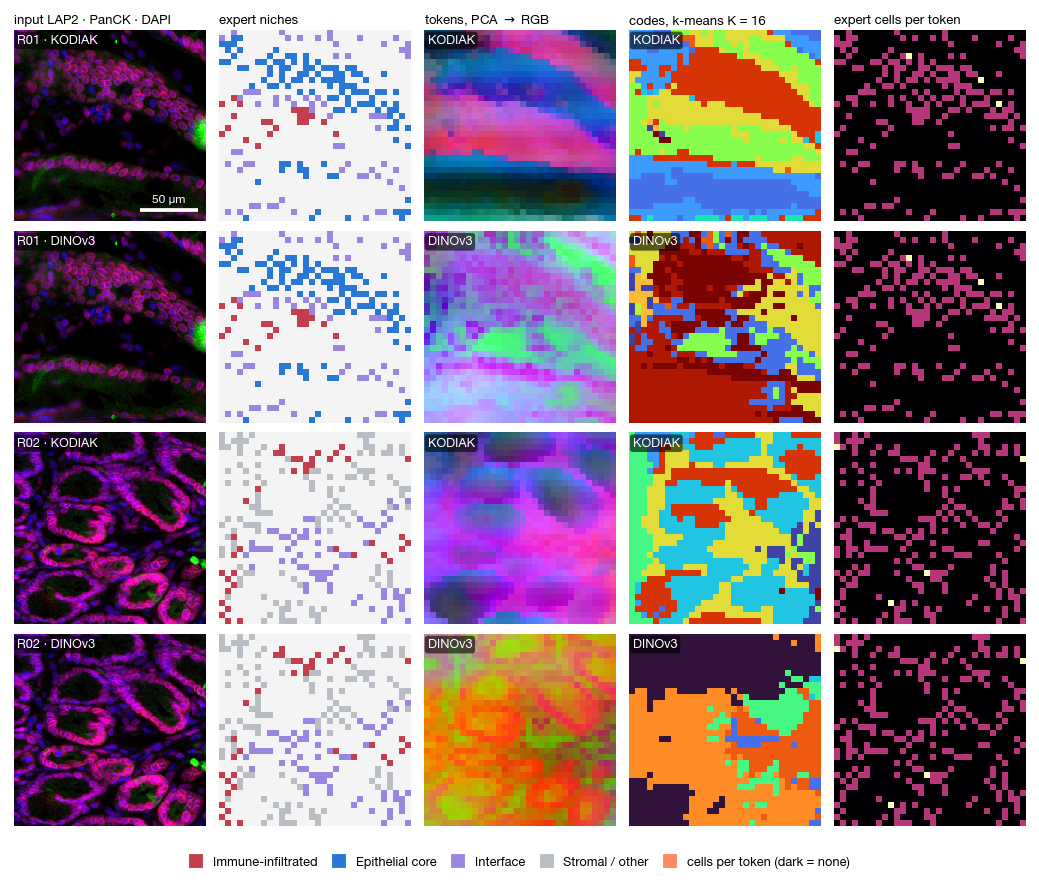

In [8]:
from sklearn.decomposition import PCA as _PCA

K_MAP = 16                                                                     # matched codebook size drawn here
CROP = 512                                                                     # px per panel; the whole region is far too large
SHOW_REGIONS = list(MAPS)[:2]
rng = np.random.default_rng(0)
gc = CROP // G                                                                 # tokens across a crop

pca_rgb, code_lab = {}, {}
for tag in ("KODIAK", "DINOv3"):
    Z = unit(X[tag])
    sub = Z[rng.choice(len(Z), min(20000, len(Z)), replace=False)]
    pc = _PCA(3, random_state=0).fit(sub)
    v = pc.transform(Z)
    lo, hi = np.percentile(v, 2, axis=0), np.percentile(v, 98, axis=0)
    pca_rgb[tag] = np.clip((v - lo) / (hi - lo), 0, 1)
    code_lab[tag] = MiniBatchKMeans(K_MAP, n_init=3, random_state=0, batch_size=4096).fit_predict(Z)
code_cmap = plt.cm.turbo(np.linspace(0, 1, K_MAP))[:, :3]

def busiest(cells, h, w):
    """Top-left token of the gc x gc window holding the most expert cells -- the crop worth looking at."""
    c = cells.reshape(h, w)
    if h <= gc or w <= gc:
        return 0, 0
    s = c.cumsum(0).cumsum(1)
    s = np.pad(s, ((1, 0), (1, 0)))
    tot = s[gc:, gc:] - s[:-gc, gc:] - s[gc:, :-gc] + s[:-gc, :-gc]
    y, x = np.unravel_index(tot.argmax(), tot.shape)
    return int(y), int(x)

COLS = ["input " + " · ".join(MARKERS), "expert niches", "tokens, PCA $\\rightarrow$ RGB", f"codes, k-means K = {K_MAP}", "expert cells per token"]
fig, axes = plt.subplots(2 * len(SHOW_REGIONS), 5, figsize=(7.6, 1.55 * 2 * len(SHOW_REGIONS) + 0.5))
fig.subplots_adjust(left=0.003, right=0.997, top=0.94, bottom=0.06, wspace=0.03, hspace=0.05)
for ri, key in enumerate(SHOW_REGIONS):
    h, w = MAPS[key]["shape"]
    sel = (TOK.region == key).values
    sub = TOK[sel]
    y0, x0 = busiest(sub.n_cells.values, h, w)
    ys, xs = slice(y0, y0 + gc), slice(x0, x0 + gc)
    niche_img = np.ones((h, w, 3)) * 0.96
    for nm, col in NICHE_COLOR.items():
        m = (sub.niche == nm).values.reshape(h, w)
        niche_img[m] = [int(col[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    for ei, tag in enumerate(("KODIAK", "DINOv3")):
        r = ri * 2 + ei
        cells = sub.n_cells.values.reshape(h, w)[ys, xs]
        panels = [MAPS[key]["rgb"][y0 * G:(y0 + gc) * G, x0 * G:(x0 + gc) * G],
                  niche_img[ys, xs],
                  pca_rgb[tag][sel].reshape(h, w, 3)[ys, xs],
                  code_cmap[code_lab[tag][sel].reshape(h, w)[ys, xs]],
                  cells]
        for c, img in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(img, cmap="magma" if c == 4 else None, interpolation="nearest")
            ax.set_axis_off()
            if r == 0:
                ax.set_title(COLS[c], fontsize=7, pad=3)
        chip(axes[r, 0], f"{short(key)} · {tag}")
        for c in (2, 3):
            chip(axes[r, c], tag)
        if ei == 0 and ri == 0:
            scalebar(axes[r, 0], CROP, um=50)
h_ = [plt.Line2D([], [], marker="s", ls="", ms=6, color=c, label=n) for n, c in NICHE_COLOR.items()] + \
     [plt.Line2D([], [], marker="s", ls="", ms=6, color=plt.cm.magma(0.75), label="cells per token (dark = none)")]
fig.legend(handles=h_, loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0), fontsize=6.8, handlelength=1.0, columnspacing=1.2)
plt.show()

**Figure 3 — Two regions through both encoders, matched.** Each panel is a 512 px crop (the densest window of the region, chosen once and shared by both rows), not the whole region. Rows come in pairs (KODIAK above, DINOv3 below) for each
region. Columns: the marker composite the encoders actually see; the expert niches; the token field reduced to RGB by a
PCA fitted on that encoder's own tokens; the matched k-means codes at K=16 with a shared colormap; and how many expert
cells fall in each token. Read the code maps against the niche map: agreement that is visible here should show up as
NMI in Figure 2, and if it does not, the eye is being convinced by colour rather than by structure.

## Reading the results

**What a claim needs.** "KODIAK's representation encodes niches better than DINOv3's" is supported only if its bar in
Figure 1 clears both the marker baseline *and* DINOv3's, with non-overlapping fold s.d., **in the PCA-matched panel**.
Clearing the marker baseline alone says the encoder beats raw intensity; clearing DINOv3 at full width but not at
matched width says the win came from token width, not from pretraining.

**What the numbers cannot say.** Folds are regions of one slide, so the s.d. is within-slide variability, not
between-slide. Every token label descends from HALO-derived annotation and the fixed phenotype gates — three of which
are marked provisional in `configs/panel.yaml` — so the niche reference inherits their uncertainty. And the niches are
themselves a k-means partition of expert-cell windows: agreement with them is agreement with one defensible summary of
the annotation, not with a ground truth.

**When to re-run.** Against the final pretraining checkpoint, not a mid-training one. Section 4 will tell you whether
the codebook was still collapsing when you looked.

In [9]:
# ---- the paper's copies: one PDF per panel at final print size, composed by main.tex ---------------------------------
PAPER = REPO / "LaTex" / "figures" / "repr"; PAPER.mkdir(parents=True, exist_ok=True)
PANEL = 1.28                                                                   # 4 x 1.28 in + gaps = one text width
def _frame(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor("#C6CBD2"); s.set_linewidth(0.5)

_meta = {"slide": SLIDE, "K_map": K_MAP, "crop_px": CROP, "crop_um": round(CROP * PX_UM, 1),
         "checkpoint": str(CKPT_INFO) if "CKPT_INFO" in dir() else None, "rows": []}
for ri, key in enumerate(SHOW_REGIONS):
    h, w = MAPS[key]["shape"]
    sel = (TOK.region == key).values
    sub = TOK[sel]
    y0, x0 = busiest(sub.n_cells.values, h, w)
    ys, xs = slice(y0, y0 + gc), slice(x0, x0 + gc)
    niche_img = np.ones((h, w, 3)) * 0.96
    for nm, col in NICHE_COLOR.items():
        m = (sub.niche == nm).values.reshape(h, w)
        niche_img[m] = [int(col[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    for ei, tag in enumerate(("KODIAK", "DINOv3")):
        cols = {"input": MAPS[key]["rgb"][y0 * G:(y0 + gc) * G, x0 * G:(x0 + gc) * G],
                "niche": niche_img[ys, xs],
                "pca":   pca_rgb[tag][sel].reshape(h, w, 3)[ys, xs],
                "code":  code_cmap[code_lab[tag][sel].reshape(h, w)[ys, xs]]}
        for cname, img in cols.items():
            f = plt.figure(figsize=(PANEL, PANEL)); ax = f.add_axes([0, 0, 1, 1])
            ax.imshow(img, interpolation="nearest"); _frame(ax)
            if cname == "input" and ri == 0 and ei == 0:
                L = 50 / PX_UM
                ax.add_patch(plt.Rectangle((CROP * 0.97 - L - 8, CROP * 0.93 - 34), L + 16, 40, fc="white",
                                           ec="none", alpha=0.85, zorder=8))
                ax.plot([CROP * 0.97 - L, CROP * 0.97], [CROP * 0.93 - 8, CROP * 0.93 - 8], color="#14181D",
                        lw=1.6, solid_capstyle="butt", zorder=9)
                ax.text(CROP * 0.97 - L / 2, CROP * 0.93 - 13, "50 µm", ha="center", va="bottom", fontsize=5.4,
                        color="#14181D", zorder=9)
            f.savefig(PAPER / f"repr_{ri}{ei}_{cname}.pdf"); plt.close(f)
        _meta["rows"].append({"region": short(key), "encoder": tag})

lg = plt.figure(figsize=(4 * PANEL + 0.2, 0.30))
lg.legend([plt.Line2D([], [], marker="s", ls="", ms=4.4, color=c) for c in NICHE_COLOR.values()],
          list(NICHE_COLOR), loc="center", ncol=len(NICHE_COLOR), fontsize=6.2, handlelength=1.0,
          handletextpad=0.4, columnspacing=1.2, borderpad=0.0, borderaxespad=0.0)
lg.savefig(PAPER / "repr_legend.pdf", bbox_inches="tight", pad_inches=0.012); plt.close(lg)

_util = {}
for tag in ("KODIAK", "DINOv3"):
    cnt = np.bincount(code_lab[tag], minlength=K_MAP)
    frac = np.sort(cnt)[::-1] / cnt.sum()
    _util[tag] = {"active": int((cnt > 0).sum()), "top_share": round(float(frac[0]), 3),
                  "codes_for_90pct": int((frac.cumsum() < 0.9).sum()) + 1}
_meta["utilization"] = _util
(PAPER / "repr.json").write_text(json.dumps(_meta, indent=1))
print(json.dumps(_meta["utilization"], indent=1))
print("wrote", len(list(PAPER.glob("repr_*.pdf"))), "panels to", PAPER)


{
 "KODIAK": {
  "active": 16,
  "top_share": 0.153,
  "codes_for_90pct": 14
 },
 "DINOv3": {
  "active": 16,
  "top_share": 0.12,
  "codes_for_90pct": 13
 }
}
wrote 19 panels to /Users/marjan/Desktop/MedAI/NeurIPSWorkshop/LaTex/figures/repr
